<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Separate spreadsheet details from totals

**Which spreadsheet cells belong in an analytical total?** We will read an authored
Excel workbook with the Apache POI worker, inspect cell types and evaluated formulas,
separate line items from summaries, and export the selected rows back to Excel.
Two charts show duplicate counting and the effect of including a return.

This is an entirely synthetic order worksheet, not business or account data. It has
one pending quantity, a real zero quantity, and deliberately stale formula caches.
We calculate **known line amounts**, not a complete order total: the pending amount
remains unknown throughout the example.

## Choose whether the selected view includes returns

`INCLUDE_RETURNS=True` includes valid negative-quantity lines. The experiment changes
only this flag to `False`. Restart the kernel and run all after editing it. This is
a selection policy; it does not change the source workbook, formula results, or the
classification of the pending quantity.

In [1]:
INCLUDE_RETURNS = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
from pathlib import Path
import haybarn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from notebook_support import finish, prose, theme

if type(INCLUDE_RETURNS) is not bool:
    raise ValueError("INCLUDE_RETURNS must be True or False.")
reconciliation = lines = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-poi/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-poi/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-poi/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-poi/notebooks/pyproject.toml.

## Attach the public Java release

The literal launcher downloads the v0.4.0 JAR, checks its pinned SHA-256 on every
launch and starts Java. It needs Java 21+ on `PATH` and `uv`; there is no local
worker build. The small helper and locked environment travel with this notebook.
Initial installation requires network access; workbook processing is local.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'excel' (TYPE vgi, LOCATION 'uv run --frozen --project . python release_jar.py Query-farm/vgi-poi v0.4.0 vgi-poi-v0.4.0.jar aed3febbcd965485b12aa28e255abff1ff2e8fdf877d1be9bc75f0e088f7ee98');
CREATE TABLE sheet_inventory AS
 SELECT * FROM excel.main.excel_sheets('assets/synthetic-orders.xlsx');
CREATE TABLE cells AS
 SELECT * FROM excel.main.read_excel('assets/synthetic-orders.xlsx');
SELECT s.name,s.rows AS row_extent,s.cols AS column_extent,
 count(c.cell_ref) AS emitted_nonblank_cells,count(DISTINCT c.row) AS rows_with_cells,
 count(c.formula) AS formula_cells
FROM sheet_inventory s LEFT JOIN cells c ON s.name=c.sheet
GROUP BY ALL ORDER BY s.name;

,name,row_extent,column_extent,emitted_nonblank_cells,rows_with_cells,formula_cells
0,Notes,1,1,1,1,0
1,Orders,30,7,55,10,8


## Read cell evidence before deciding what a row means

The directory's row count is a **last-row extent**, not a count of data records. Our
Orders sheet contains a blank cell at row 30, while `read_excel` emits only nonblank
cells. Coordinates `row` and `col` are zero-based; `cell_ref` is the familiar A1 reference.

POI evaluates the local formulas. Their authored OOXML caches all contain 999999,
but the returned values come from evaluation. The pending quantity produces
`#VALUE!`; its cell type is still `FORMULA`. Preserve both type and value instead of
assuming every formula is numeric. External-workbook links are not resolved; this
fixture contains none and does not exercise cached-value fallback for such links.

In [4]:
%%sql
SELECT sheet,cell_ref,type,value,formula
FROM cells WHERE sheet='Orders' AND (col IN (3,5) OR cell_ref='B2')
ORDER BY row,col;

,sheet,cell_ref,type,value,formula
0,Orders,D1,STRING,units,None
1,Orders,F1,STRING,amount_cents,None
2,Orders,B2,STRING,0001,None
3,Orders,D2,NUMERIC,3,None
4,Orders,F2,FORMULA,3750,D2*E2
5,Orders,D3,NUMERIC,2,None
6,Orders,F3,FORMULA,4400,D3*E3
7,Orders,F4,FORMULA,8150,SUM(F2:F3)
8,Orders,D5,NUMERIC,-1,None
9,Orders,F5,FORMULA,-1250,D5*E5


## Reshape the declared worksheet schema in SQL

For this known worksheet, A–G mean kind, order ID, SKU, units, integer unit price in
cents, formula amount in cents, and approval flag. The `kind` column explicitly labels
line, subtotal, grand-total and note rows. This mapping is a fixture contract, not an
attempt to infer arbitrary spreadsheet layouts. A header check below guards it.

Keep order IDs as strings so `0001` retains its leading zeros. Accept only integer
numeric quantities and cents. The pending text remains NULL after parsing; the
legitimate numeric zero remains zero. All valid line rows in this fixture are approved.

In [5]:
%%sql
CREATE TABLE worksheet_rows AS
SELECT row+1 AS excel_row,
 max(value) FILTER(WHERE col=0) AS kind,
 max(value) FILTER(WHERE col=1) AS order_id,
 max(value) FILTER(WHERE col=2) AS sku,
 max(value) FILTER(WHERE col=3) AS units_text,
 max(type) FILTER(WHERE col=3) AS units_type,
 max(value) FILTER(WHERE col=4) AS unit_cents_text,
 max(type) FILTER(WHERE col=4) AS unit_cents_type,
 max(value) FILTER(WHERE col=5) AS amount_text,
 max(type) FILTER(WHERE col=5) AS amount_type,
 max(formula) FILTER(WHERE col=5) AS amount_formula,
 max(value) FILTER(WHERE col=6) AS approved_text
FROM cells WHERE sheet='Orders' AND row>0 GROUP BY row;
CREATE TABLE typed_rows AS
SELECT *,
 CASE WHEN units_type='NUMERIC' AND regexp_full_match(units_text,'-?[0-9]+')
      THEN try_cast(units_text AS INTEGER) END AS units,
 CASE WHEN unit_cents_type='NUMERIC' AND regexp_full_match(unit_cents_text,'[0-9]+')
      THEN try_cast(unit_cents_text AS BIGINT) END AS unit_cents,
 CASE WHEN regexp_full_match(amount_text,'-?[0-9]+')
      THEN try_cast(amount_text AS BIGINT) END AS amount_cents,
 try_cast(approved_text AS BOOLEAN) AS approved
FROM worksheet_rows;
CREATE TABLE classified AS
SELECT *,CASE
 WHEN kind<>'line' THEN 'Summary or note'
 WHEN order_id IS NULL OR sku IS NULL THEN 'Missing identity'
 WHEN units IS NULL OR unit_cents IS NULL OR amount_cents IS NULL THEN 'Unknown quantity or amount'
 WHEN approved IS DISTINCT FROM true THEN 'Not approved'
 WHEN amount_cents<>units::BIGINT*unit_cents THEN 'Formula mismatch'
 ELSE 'Valid line' END AS row_state
FROM typed_rows;
SELECT excel_row,kind,order_id,units_text,units,amount_text,amount_cents,row_state
FROM classified ORDER BY excel_row;

,excel_row,kind,order_id,units_text,units,amount_text,amount_cents,row_state
0,2,line,0001,3,3,3750,3750,Valid line
1,3,line,0002,2,2,4400,4400,Valid line
2,4,subtotal,None,None,<NA>,8150,8150,Summary or note
3,5,line,0003,-1,-1,-1250,-1250,Valid line
4,6,line,0004,4,4,3000,3000,Valid line
5,7,line,0005,0,0,0,0,Valid line
6,8,line,0006,pending,<NA>,#VALUE!,<NA>,Unknown quantity or amount
7,10,grand_total,None,None,<NA>,9900,9900,Summary or note
8,11,note,Synthetic known amounts only; pending quantity...,None,<NA>,None,<NA>,Summary or note


## A numeric amount column can count the same work twice

Summing every parseable cell in column F mixes detail with subtotal and grand-total
formulas. A successful numeric cast is not sufficient to establish the row's grain.
The chart compares that naive sum with the known valid line sum and the authored
grand-total cell. All three exclude the unresolved error value; none makes it zero.
This audit always includes returns and remains fixed during the selection experiment.

In [6]:
%%sql reconciliation <<
SELECT sum(amount_cents) AS all_numeric_amount_cells,
 sum(amount_cents) FILTER(WHERE row_state='Valid line') AS known_line_amount,
 sum(amount_cents) FILTER(WHERE kind='subtotal') AS subtotal_cells,
 sum(amount_cents) FILTER(WHERE kind='grand_total') AS grand_total_cell,
 count(*) FILTER(WHERE kind='line') AS line_rows,
 count(*) FILTER(WHERE kind='line' AND row_state<>'Valid line') AS unresolved_lines,
 count(*) FILTER(WHERE row_state='Valid line' AND units=0) AS zero_lines
FROM classified;

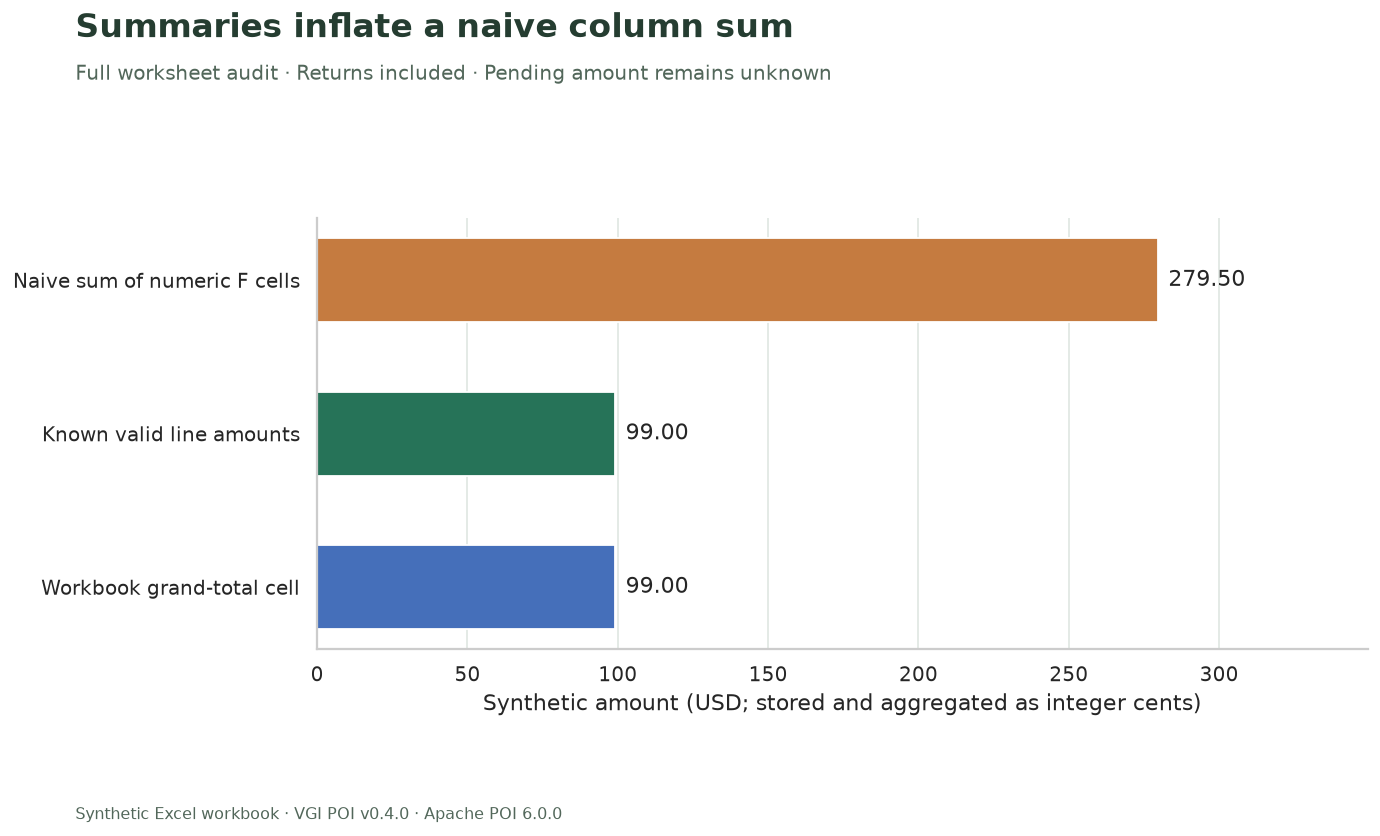

The naive sum is **279.50 USD**, compared with **99.00 USD** of known valid line amounts. The difference, **180.50 USD**, comes from adding summary cells to their underlying detail. There are **1 unresolved line(s)** and **1 valid zero-quantity line(s)**. The matching grand-total cell covers the authored known rows; it does not resolve the pending line.

In [7]:
r = reconciliation.iloc[0]
fig, ax = plt.subplots(figsize=(11, 6.5))
values = (
    np.array([r.all_numeric_amount_cells, r.known_line_amount, r.grand_total_cell], dtype=float)
    / 100
)
bars = ax.barh(
    ["Naive sum of numeric F cells", "Known valid line amounts", "Workbook grand-total cell"],
    values,
    color=["#c57b40", "#267358", "#456fba"],
    height=0.55,
)
ax.bar_label(bars, labels=[f"{v:,.2f}" for v in values], padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Synthetic amount (USD; stored and aggregated as integer cents)")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Summaries inflate a naive column sum",
    "Full worksheet audit · Returns included · Pending amount remains unknown",
    "01_amount_grain.png",
    bottom=0.12,
)
prose(
    f"The naive sum is **{r.all_numeric_amount_cells / 100:,.2f} USD**, compared with "
    f"**{r.known_line_amount / 100:,.2f} USD** of known valid line amounts. "
    f"The difference, **{(r.all_numeric_amount_cells - r.known_line_amount) / 100:,.2f} USD**, "
    "comes from adding summary cells to their underlying detail. "
    f"There are **{int(r.unresolved_lines)} unresolved line(s)** and **{int(r.zero_lines)} valid zero-quantity line(s)**. "
    "The matching grand-total cell covers the authored known rows; it does not resolve the pending line."
)

## Make the return policy visible without dropping the audit

Selection is applied only after classification. The chart keeps every valid line,
including the zero-quantity sample, and marks any excluded return with hatching.
The unresolved pending line remains in `classified` and is counted above, but has no
numeric bar. Excluding a negative return increases the selected known amount; it
would be misleading to describe that change as new sales.

In [8]:
%%sql
CREATE TABLE selected_lines AS
SELECT excel_row,order_id,sku,units,unit_cents,amount_cents,units<0 AS is_return
FROM classified WHERE row_state='Valid line' AND ({{ INCLUDE_RETURNS }} OR units>=0);
SELECT * FROM selected_lines ORDER BY excel_row;

,excel_row,order_id,sku,units,unit_cents,amount_cents,is_return
0,2,0001,MUG,3,1250,3750,False
1,3,0002,TEE,2,2200,4400,False
2,5,0003,MUG,-1,1250,-1250,True
3,6,0004,POSTER,4,750,3000,False
4,7,0005,SAMPLE,0,500,0,False


In [9]:
%%sql lines <<
SELECT c.excel_row,c.order_id,c.sku,c.units,c.amount_cents,s.order_id IS NOT NULL AS selected
FROM classified c LEFT JOIN selected_lines s USING(excel_row)
WHERE c.row_state='Valid line' ORDER BY c.excel_row;

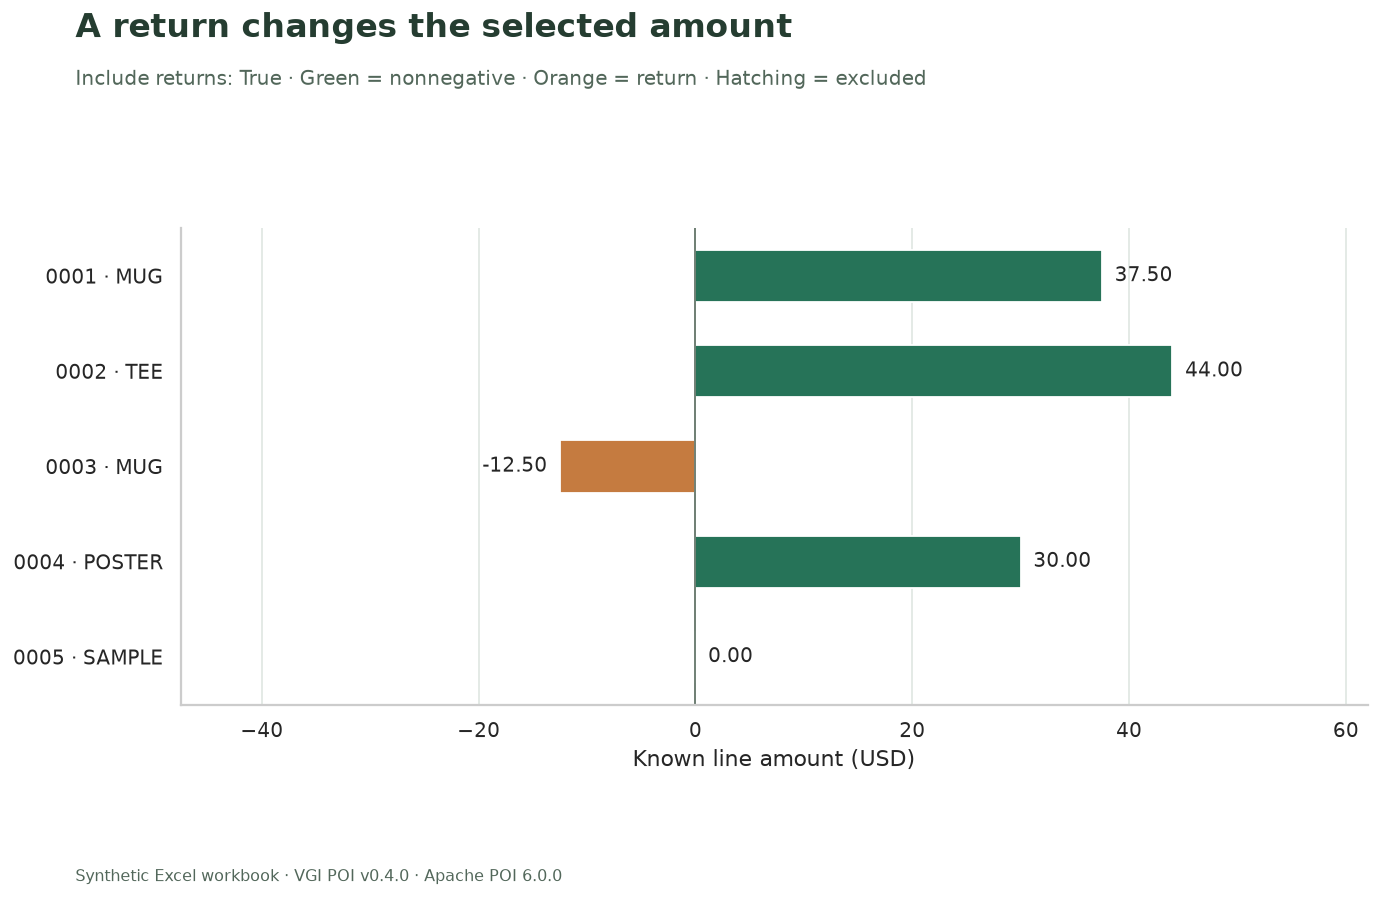

The policy selects **5 of 5 valid lines**, totaling **99.00 USD**. Excluded known lines sum to **0.00 USD**. Selected plus excluded known amounts reconcile to the full valid-line sum. The pending row still has no amount and is not part of either known sum.

In [10]:
fig, ax = plt.subplots(figsize=(11, 7))
values = lines.amount_cents.to_numpy(dtype=float) / 100
labels = [f"{x.order_id} · {x.sku}" for x in lines.itertuples()]
colors = ["#267358" if v >= 0 else "#c57b40" for v in values]
bars = ax.barh(labels, values, color=colors, height=0.55)
for bar, selected in zip(bars, lines.selected, strict=True):
    if not selected:
        bar.set_facecolor("#e9ece9")
        bar.set_edgecolor("#7a847d")
        bar.set_hatch("///")
for i, (v, selected) in enumerate(zip(values, lines.selected, strict=True)):
    ax.annotate(
        f"{v:,.2f}" + (" · excluded" if not selected else ""),
        (v, i),
        xytext=(7 if v >= 0 else -7, 0),
        textcoords="offset points",
        ha="left" if v >= 0 else "right",
        va="center",
        fontsize=11,
    )
ax.axvline(0, color="#65766a", lw=1)
ax.set_xlim(min(values.min(), 0) - 35, max(values.max(), 0) + 18)
ax.invert_yaxis()
ax.set_xlabel("Known line amount (USD)")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "A return changes the selected amount",
    f"Include returns: {INCLUDE_RETURNS} · Green = nonnegative · Orange = return · Hatching = excluded",
    "02_selected_lines.png",
    bottom=0.12,
)
selected_cents = int(lines.loc[lines.selected, "amount_cents"].sum())
excluded_cents = int(lines.loc[~lines.selected, "amount_cents"].sum())
prose(
    f"The policy selects **{int(lines.selected.sum())} of {len(lines)} valid lines**, totaling "
    f"**{selected_cents / 100:,.2f} USD**. Excluded known lines sum to **{excluded_cents / 100:,.2f} USD**. "
    "Selected plus excluded known amounts reconcile to the full valid-line sum. "
    "The pending row still has no amount and is not part of either known sum."
)

## Export the typed selected relation

`write_xlsx` consumes a relation and returns workbook bytes. We export values with
text IDs, integer quantities/cents and a boolean return flag. This creates a new
worksheet; it does not preserve the original workbook's formulas, formatting or notes.
Small integer cents avoid floating-point currency arithmetic in SQL. Large integers
and unsupported Arrow types need separate round-trip checks; this is not a general
lossless serialization claim.

The pinned worker emits a workbook-so-far for each input batch. This tiny selection
is verified to return exactly one BLOB. The save cell refuses multiple results instead
of choosing an arbitrary partial workbook. It writes only the notebook's ignored
`validation/export/selected-lines.xlsx` file.

In [11]:
%%sql
CREATE TABLE export_workbooks AS
SELECT * FROM excel.main.write_xlsx(
 (SELECT order_id,sku,units,amount_cents,is_return FROM selected_lines ORDER BY excel_row),
 sheet_name := 'Selected',header := true);
SELECT count(*) AS workbook_blobs,min(octet_length(xlsx)) AS minimum_bytes,
 bool_and(excel.main.detect_excel(xlsx)='xlsx') AS all_detect_as_xlsx
FROM export_workbooks;

,workbook_blobs,minimum_bytes,all_detect_as_xlsx
0,1,3634,True


In [12]:
workbooks = con.execute("SELECT xlsx FROM export_workbooks").fetchall()
if len(workbooks) != 1:
    raise ValueError(
        "Expected one complete workbook for this small input; refusing an ambiguous multi-batch export."
    )
export_path = Path("validation/export/selected-lines.xlsx")
export_path.parent.mkdir(parents=True, exist_ok=True)
staged_path = export_path.with_suffix(".xlsx.tmp")
staged_path.write_bytes(bytes(workbooks[0][0]))
staged_path.replace(export_path)
prose(
    "Saved **validation/export/selected-lines.xlsx**. The next SQL cell rereads those exact bytes with the real worker."
)

Saved **validation/export/selected-lines.xlsx**. The next SQL cell rereads those exact bytes with the real worker.

## Read the saved workbook back through VGI

The reader requires a literal document argument, so a path bridges the write/read
steps. A direct subquery BLOB argument is not supported by this table function. The
round trip checks values and cell types, including string IDs and boolean flags.
Order is not used as the join key; the exported order ID identifies each fixture row.

In [13]:
%%sql
CREATE TABLE roundtrip_cells AS
SELECT * FROM excel.main.read_excel('validation/export/selected-lines.xlsx',sheet := 'Selected');
CREATE TABLE roundtrip_rows AS
SELECT row,
 max(value) FILTER(WHERE col=0) AS order_id,
 max(value) FILTER(WHERE col=1) AS sku,
 try_cast(max(value) FILTER(WHERE col=2) AS INTEGER) AS units,
 try_cast(max(value) FILTER(WHERE col=3) AS BIGINT) AS amount_cents,
 try_cast(max(value) FILTER(WHERE col=4) AS BOOLEAN) AS is_return
FROM roundtrip_cells WHERE row>0 GROUP BY row;
SELECT * FROM roundtrip_rows ORDER BY order_id;

,row,order_id,sku,units,amount_cents,is_return
0,1,0001,MUG,3,3750,False
1,2,0002,TEE,2,4400,False
2,3,0003,MUG,-1,-1250,True
3,4,0004,POSTER,4,3000,False
4,5,0005,SAMPLE,0,0,False


## Distinguish a missing sheet from an invalid document

Both calls below return no cell rows. Format detection and sheet inventory explain
why: one document is an XLSX without the requested sheet, while the other is plain
text. A zero-row result alone is not a successful workbook validation. Parsing errors
are logged by the worker and may be surfaced as no rows rather than a query failure.

In [14]:
%%sql
CREATE TABLE input_diagnostics AS
SELECT 'Valid workbook, missing sheet' AS case_name,
 excel.main.detect_excel((SELECT content FROM read_blob('assets/synthetic-orders.xlsx'))) AS detected_format,
 (SELECT count(*) FROM excel.main.read_excel('assets/synthetic-orders.xlsx',sheet := 'Missing')) AS cell_rows
UNION ALL
SELECT 'Not a workbook',
 excel.main.detect_excel((SELECT content FROM read_blob('assets/not-a-workbook.txt'))),
 (SELECT count(*) FROM excel.main.read_excel('assets/not-a-workbook.txt'));
SELECT * FROM input_diagnostics;

,case_name,detected_format,cell_rows
0,"Valid workbook, missing sheet",xlsx,0
1,Not a workbook,None,0


## Reconcile the selection and the round trip

These checks preserve the source grain, separate the error from zero, reconcile the
selected and excluded known amounts, and verify the export's exact small values and
cell types. They apply to both return policies.

In [15]:
%%sql checks <<
SELECT 'Declared headers match workbook' AS check_name,
 (SELECT string_agg(value,',' ORDER BY col) FROM cells WHERE sheet='Orders' AND row=0)
 ='kind,order_id,sku,units,unit_cents,amount_cents,approved' AS passed
UNION ALL SELECT 'Every emitted body row classified',
 (SELECT count(*) FROM classified)=(SELECT count(DISTINCT row) FROM cells WHERE sheet='Orders' AND row>0)
UNION ALL SELECT 'Valid line formula agrees with SQL multiplication',
 NOT EXISTS(SELECT 1 FROM classified WHERE row_state='Valid line' AND amount_cents<>units::BIGINT*unit_cents)
UNION ALL SELECT 'Known line total agrees with authored summary',
 (SELECT sum(amount_cents) FROM classified WHERE row_state='Valid line')=(SELECT amount_cents FROM classified WHERE kind='grand_total')
UNION ALL SELECT 'All original local formula caches reevaluated',
 NOT EXISTS(SELECT 1 FROM cells WHERE formula IS NOT NULL AND value='999999')
UNION ALL SELECT 'Pending quantity remains unknown with formula error',
 EXISTS(SELECT 1 FROM classified WHERE units_text='pending' AND units IS NULL AND amount_cents IS NULL AND amount_text='#VALUE!')
UNION ALL SELECT 'Numeric zero retained as a valid line',
 EXISTS(SELECT 1 FROM selected_lines WHERE units=0 AND amount_cents=0)
UNION ALL SELECT 'Selection and excluded values reconcile',
 (SELECT sum(amount_cents) FROM selected_lines)+coalesce((SELECT sum(c.amount_cents) FROM classified c ANTI JOIN selected_lines s USING(excel_row) WHERE c.row_state='Valid line'),0)
 =(SELECT sum(amount_cents) FROM classified WHERE row_state='Valid line')
UNION ALL SELECT 'Export has one valid XLSX result',
 (SELECT count(*)=1 AND bool_and(excel.main.detect_excel(xlsx)='xlsx') FROM export_workbooks)
UNION ALL SELECT 'Round-trip values equal selected rows in both directions',
 NOT EXISTS(SELECT order_id,sku,units,amount_cents,is_return FROM selected_lines
 EXCEPT SELECT order_id,sku,units,amount_cents,is_return FROM roundtrip_rows)
 AND NOT EXISTS(SELECT order_id,sku,units,amount_cents,is_return FROM roundtrip_rows
 EXCEPT SELECT order_id,sku,units,amount_cents,is_return FROM selected_lines)
UNION ALL SELECT 'Round-trip row count and IDs preserved',
 (SELECT count(*) FROM roundtrip_rows)=(SELECT count(*) FROM selected_lines)
 AND (SELECT count(DISTINCT order_id) FROM roundtrip_rows)=(SELECT count(*) FROM selected_lines)
UNION ALL SELECT 'Exported text numeric and boolean cell types preserved',
 NOT EXISTS(SELECT 1 FROM roundtrip_cells WHERE row>0 AND type<>CASE WHEN col IN(0,1) THEN 'STRING' WHEN col IN(2,3) THEN 'NUMERIC' ELSE 'BOOLEAN' END)
UNION ALL SELECT 'Missing sheet and bad input remain distinct',
 (SELECT count(*)=2 AND sum(cell_rows)=0 AND count(detected_format)=1 FROM input_diagnostics);

In [16]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} checks passed.** The export preserves the selected fixture rows, and the pending amount remains outside every known sum."
)

**13 checks passed.** The export preserves the selected fixture rows, and the pending amount remains outside every known sum.

## Experiment · exclude the return, keep the source fixed

Change only `INCLUDE_RETURNS` from `True` to `False`, restart, and run all. Predict
which chart changes and why the selected amount rises when a negative line is omitted.
Compare the row count and amount in the reread export. The first chart, original cell
inventory and pending-line diagnosis should remain unchanged.

The new selection is a different scope, not a correction to the workbook or evidence
of additional activity. Neither selection resolves the unknown quantity. Reset
`INCLUDE_RETURNS=True` to restore the saved default.

In [17]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)